In [63]:
import pandas as pd
from pathlib import Path

In [64]:
# Desktop loading
DATA_ROOT = Path(
    r"../data/"
)

In [65]:
def load_market_data(
    exchange,
    symbol,
    data_type="book",
    date=None,
):
    path = (
        DATA_ROOT
        / exchange.upper()
        / symbol.upper()
        / data_type
    )

    if date is not None:
        path = path / date

    if not path.exists():
        raise FileNotFoundError(
            f"No data found at:\n{path}"
        )

    df = pd.read_parquet(path)

    return df

In [66]:
hl_pendle = load_market_data(
    "HYPERLIQUID",
    "PENDLE-USD-PERP",
    "book"
)

binance_pendle = load_market_data(
    "BINANCE",
    "PENDLE-USDT",
    "book"
)


In [68]:
hl_pendle.head(1)

,exchange,symbol,bid,bid_size,ask,ask_size,mid,spread,spread_bps,imbalance,microprice,exchange_timestamp,receipt_timestamp
0,HYPERLIQUID,PENDLE-USD-PERP,2.3816,58.0,2.3823,163.0,2.38195,0.0007,2.938769,-0.475113,2.381784,1.790640e+09,1.790640e+09


In [69]:
b = binance_pendle.copy()

b["datetime"] = pd.to_datetime(
    b["receipt_timestamp"],
    unit="s",
    utc=True
)

b = (
    b
    .set_index("datetime")
    .sort_index()
)

h = hl_pendle.copy()

h["datetime"] = pd.to_datetime(
    h["receipt_timestamp"],
    unit="s",
    utc=True
)

h = (
    h
    .set_index("datetime")
    .sort_index()
)

In [76]:
h

,exchange,symbol,bid,bid_size,ask,ask_size,mid,spread,spread_bps,imbalance,microprice,exchange_timestamp,receipt_timestamp
datetime,,,,,,,,,,,,,
2026-09-28 07:39:27.913859129+00:00,HYPERLIQUID,PENDLE-USD-PERP,2.4409,458.0,2.4419,94.0,2.44140,0.0010,4.096010,0.659420,2.441730,1.790581e+09,1.790581e+09
2026-09-28 07:39:28.554440975+00:00,HYPERLIQUID,PENDLE-USD-PERP,2.4410,654.0,2.4419,94.0,2.44145,0.0009,3.686334,0.748663,2.441787,1.790581e+09,1.790581e+09
2026-09-28 07:39:34.025192738+00:00,HYPERLIQUID,PENDLE-USD-PERP,2.4426,654.0,2.4432,94.0,2.44290,0.0006,2.456097,0.748663,2.443125,1.790581e+09,1.790581e+09
2026-09-28 07:39:39.122505426+00:00,HYPERLIQUID,PENDLE-USD-PERP,2.4424,654.0,2.4433,95.0,2.44285,0.0009,3.684221,0.746328,2.443186,1.790581e+09,1.790581e+09
2026-09-28 07:39:44.699936867+00:00,HYPERLIQUID,PENDLE-USD-PERP,2.4430,654.0,2.4436,204.0,2.44330,0.0006,2.455695,0.524476,2.443457,1.790581e+09,1.790581e+09
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-02 10:59:30.512788534+00:00,HYPERLIQUID,PENDLE-USD-PERP,2.4465,516.0,2.4469,32.0,2.44670,0.0004,1.634855,0.883212,2.446877,1.790939e+09,1.790939e+09
2026-10-02 10:59:35.778620720+00:00,HYPERLIQUID,PENDLE-USD-PERP,2.4472,56.0,2.4476,140.0,2.44740,0.0004,1.634388,-0.428571,2.447314,1.790939e+09,1.790939e+09
2026-10-02 10:59:41.200215101+00:00,HYPERLIQUID,PENDLE-USD-PERP,2.4472,56.0,2.4477,190.0,2.44745,0.0005,2.042943,-0.544715,2.447314,1.790939e+09,1.790939e+09


In [71]:
# Include both 'mid' and 'bid' in the selection filter
b_100ms = (
    b[["mid", "bid", 'ask', 'bid_size', 'ask_size', 'imbalance', 'microprice']]
    .resample("100ms")
    .last()
    .ffill()
    .rename(columns={"mid": "bin_mid", "bid": "bin_bid", 
                    'bid_size':'bid_size_bin', 'ask_size':'ask_size_bin',
                    'imbalance':'imbalance_bin', 'microprice':'microprice_bin'})
)

h_100ms = (
    h[["mid", "bid", 'bid_size', 'ask_size', 'imbalance', 'microprice']]
    .resample("100ms")
    .last()
    .ffill()
    .rename(columns={"mid": "hl_mid", "bid": "hl_bid",
                    'bid_size':'bid_size_hl', 'ask_size':'ask_size_hl',
                    'imbalance':'imbalance_hl', 'microprice':'microprice_hl'})
)

# Merge them on their timestamp indexes
df = b_100ms.join(h_100ms, how="inner")
df.tail()

,bin_mid,bin_bid,ask,bid_size_bin,ask_size_bin,imbalance_bin,microprice_bin,hl_mid,hl_bid,bid_size_hl,ask_size_hl,imbalance_hl,microprice_hl
datetime,,,,,,,,,,,,,
2026-10-02 10:59:51.500000+00:00,2.4455,2.445,2.446,16.0,318.1,-0.90422,2.445048,2.44730,2.4471,170.0,35.0,0.658537,2.447432
2026-10-02 10:59:51.600000+00:00,2.4455,2.445,2.446,16.0,318.1,-0.90422,2.445048,2.44730,2.4471,170.0,35.0,0.658537,2.447432
2026-10-02 10:59:51.700000+00:00,2.4455,2.445,2.446,16.0,318.1,-0.90422,2.445048,2.44730,2.4471,170.0,35.0,0.658537,2.447432
2026-10-02 10:59:51.800000+00:00,2.4455,2.445,2.446,16.0,318.1,-0.90422,2.445048,2.44730,2.4471,170.0,35.0,0.658537,2.447432
2026-10-02 10:59:51.900000+00:00,2.4455,2.445,2.446,16.0,318.1,-0.90422,2.445048,2.44725,2.4471,170.0,35.0,0.658537,2.447349


In [72]:
df['microprice_diff'] = df['microprice_hl'] - df['microprice_bin']
df["mid_diff"] = (
    df["hl_mid"]
    - df["bin_mid"]
)

df["reference_mid"] = (
    df["hl_mid"]
    + df["bin_mid"]
) / 2

df["mid_diff_bps"] = (
    df["hl_mid"]
    - df["bin_mid"]
) / df["reference_mid"] * 10_000

# Get EMA calculation

<Axes: xlabel='datetime'>

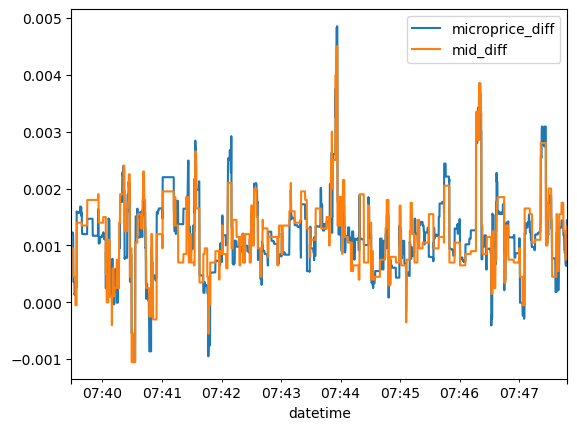

In [73]:
df[['microprice_diff', 'mid_diff']].iloc[0:5_000].plot()

Hyperliquid PENDLE-USD (tier 6): fees                        0.24
Hyperliquid PENDLE-USD (tier 6): half-spread (taker legs)    0.18
Binance PENDLE-USDT (VIP 0): fees                            4.30
Binance PENDLE-USDT (VIP 0): half-spread (taker legs)        0.20
TOTAL round-trip cost                                        4.92

break-even move  : 4.92 bps  (= 49 USD per 100,000 notional)
deviation |x| >= cost : 12.2% of bars
best TP in grid  : 12 bps  EV +2.66 bps  hit 54%


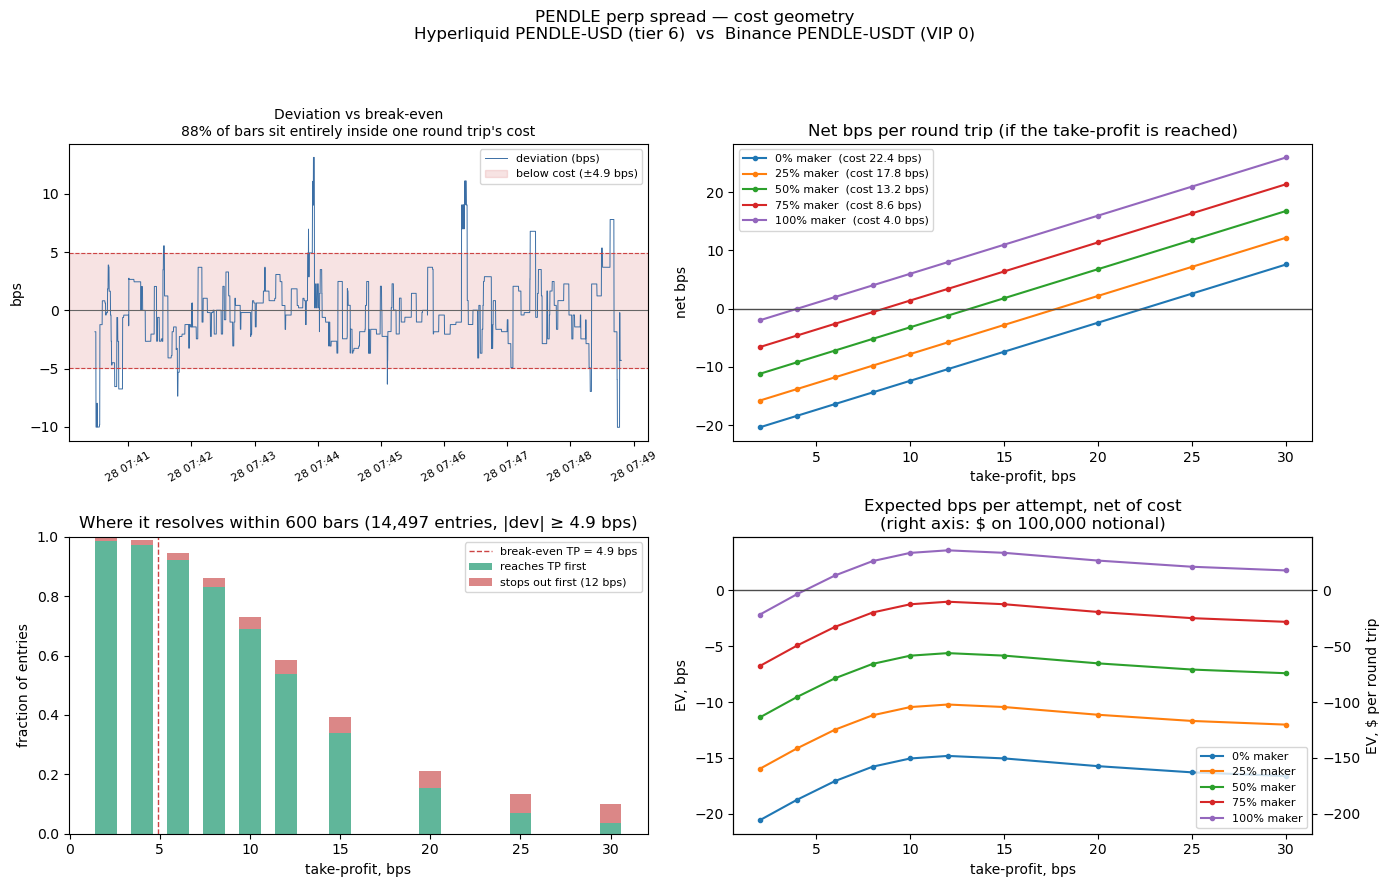

In [75]:
from spread_cost import plot_pnl, cost_breakdown

ref        = (df.hl_mid + df.bin_mid) / 2
spread_bps = (df.hl_mid - df.bin_mid) / ref * 1e4

fig, res = plot_pnl(spread_bps, taker=0.05, maker=0.95,
                    stop_bps=12, horizon_bars=600)   # 600 bars = 60s at 100ms